## 1. Import libraries

In [1]:
# install the export stuff
!pip -q install onnx onnxscript onnxruntime

# the big toolbox
import random                      # for random numbers
import json                        # for saving the scaler for the website
import numpy as np                 # math with lists of numbers
import pandas as pd                # excel but for python
import matplotlib.pyplot as plt    # makes pictures
import torch                       # PyTorch = the brain builder
from torch import nn               # nn = neural network parts
from torch.utils.data import TensorDataset, DataLoader   # hands data to the brain in small bites

from sklearn.model_selection import train_test_split     # cuts data into study pile and exam pile
from sklearn.preprocessing import StandardScaler         # squishes numbers to the same size

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# use the fast GPU if we have one, otherwise just use the slow normal chip
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("We are using:", device)

We are using: cuda


## 2. Load the data and look at it

In [2]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)      # the flower table is already inside scikit-learn
df = iris.frame.copy()               # copy so we don't break the original

# give the columns short friendly names
feature_names = ["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]
df.columns = feature_names + ["species"]

print(df.head())
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())

# species is already a number here: 0, 1, 2
class_names = list(iris.target_names)
print("Species:", {name: i for i, name in enumerate(class_names)})
print(df["species"].value_counts().sort_index())

X = df[feature_names].to_numpy(dtype=np.float32)
y = df["species"].to_numpy().astype(np.int64)

   sepal_length_cm  sepal_width_cm  petal_length_cm  petal_width_cm  species
0              5.1             3.5              1.4             0.2        0
1              4.9             3.0              1.4             0.2        0
2              4.7             3.2              1.3             0.2        0
3              4.6             3.1              1.5             0.2        0
4              5.0             3.6              1.4             0.2        0
Shape: (150, 5)
Missing values: 0
Species: {np.str_('setosa'): 0, np.str_('versicolor'): 1, np.str_('virginica'): 2}
species
0    50
1    50
2    50
Name: count, dtype: int64


## 3. Split the data and scale it

In [3]:
# stratify=y = both piles get the same mix of species
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20,
                                                    random_state=SEED, stratify=y)

raw_test = X_test.copy()    # keep RAW rows for the website demo buttons

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype("float32")   # learn rule from study pile only
X_test = scaler.transform(X_test).astype("float32")

print("Train:", len(X_train), " Test:", len(X_test), " Features:", X_train.shape[1])

loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train)),
                    batch_size=16, shuffle=True)

Xte = torch.tensor(X_test).to(device)
actual = y_test

Train: 120  Test: 30  Features: 4


## 4. Build three PyTorch models

In [4]:
# This is the brain. It is just a stack of Linear + ReLU pancakes.
class Net(nn.Module):
    def __init__(self, widths, n_outputs=1):
        super().__init__()
        layers = []
        how_many_inputs = X_train.shape[1]

        for w in widths:
            layers.append(nn.Linear(how_many_inputs, w))   # a Linear
            layers.append(nn.ReLU())                       # ReLU = "if negative, make it zero"
            how_many_inputs = w

        layers.append(nn.Linear(how_many_inputs, n_outputs))   # last  gives the final answer
        self.net = nn.Sequential(*layers)              # stack them all up

    def forward(self, x):
        return self.net(x)    # push the data through the stack

# three brains: small, medium, big. we will see which one wins.
configs = {
    "Small [16]": [16],
    "Medium [64,32]": [64, 32],
    "Large [128,64,32]": [128, 64, 32],
}

In [5]:
# The brain outputs 3 scores, one per species. Biggest score wins.
# CrossEntropyLoss does the softmax for us, so no Softmax layer in the model.
def train(widths, epochs=150):
    model = Net(widths, n_outputs=3).to(device)     # 3 outputs = 3 species
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-4)
    loss_function = nn.CrossEntropyLoss()           # "how wrong is a multi-choice guess"
    history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            loss = loss_function(model(xb), yb)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(xb)

        history.append(total_loss / len(loader.dataset))

    return model, history

## 5. Train all three and compare (F1 is the main score)

In [6]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

models = {}
histories = {}
rows = []

for name, widths in configs.items():
    print("Training", name, "...")
    model, hist = train(widths)
    model.eval()

    with torch.no_grad():
        logits = model(Xte).cpu().numpy()
    pred = logits.argmax(axis=1)          # pick the species with the biggest score

    models[name] = model
    histories[name] = hist

    # average="macro" = score each species separately, then average
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(actual, pred),
        "Precision": precision_score(actual, pred, average="macro", zero_division=0),
        "Recall": recall_score(actual, pred, average="macro", zero_division=0),
        "F1": f1_score(actual, pred, average="macro", zero_division=0),
    })

results = pd.DataFrame(rows).sort_values("F1", ascending=False, kind="stable")
print(results.round(3))

best_name = results.iloc[0]["Model"]
best = models[best_name]
print("WINNER:", best_name)

Training Small [16] ...
Training Medium [64,32] ...
Training Large [128,64,32] ...
               Model  Accuracy  Precision  Recall     F1
0         Small [16]     0.967      0.970   0.967  0.967
2  Large [128,64,32]     0.967      0.970   0.967  0.967
1     Medium [64,32]     0.933      0.933   0.933  0.933
WINNER: Small [16]


## 6. Confusion matrix, correlation matrix and other pictures

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



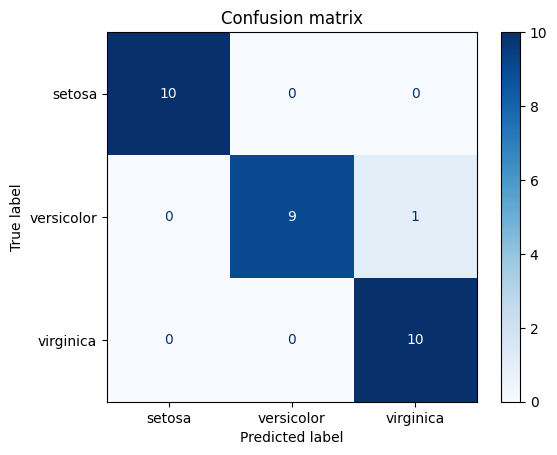

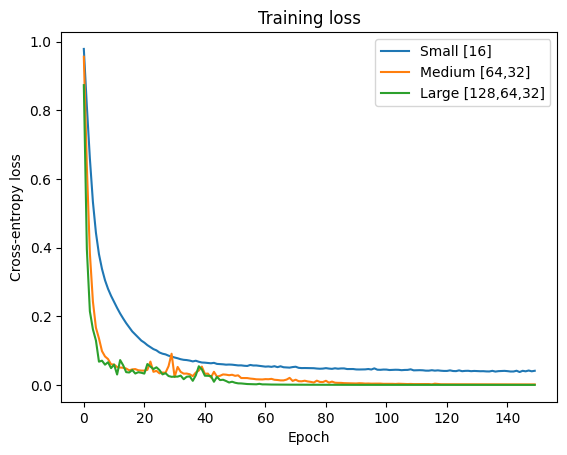

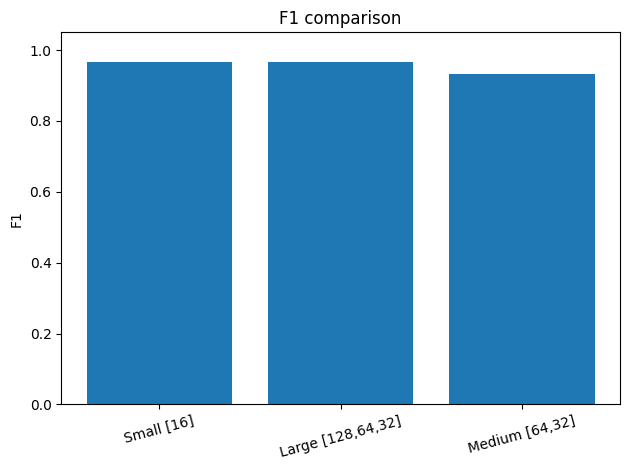

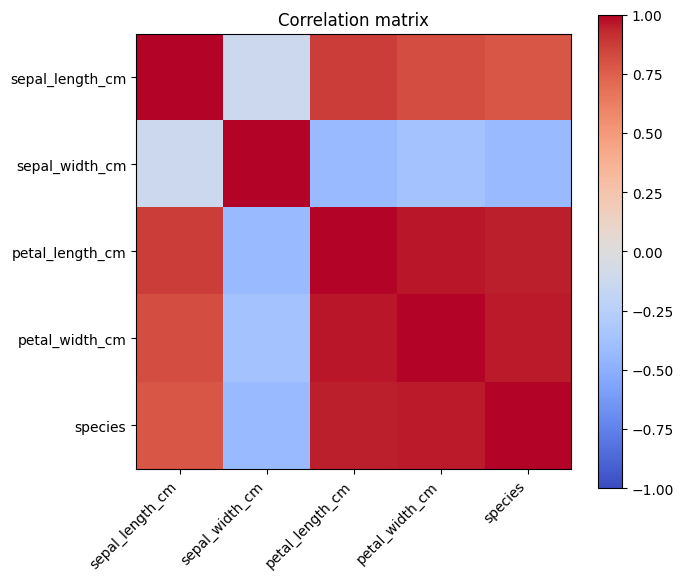

In [7]:
with torch.no_grad():
    pred = best(Xte).cpu().numpy().argmax(axis=1)

# the full report card
print(classification_report(actual, pred, target_names=class_names, zero_division=0))

# Confusion matrix: rows = truth, columns = guess. Anything off the diagonal = a mistake.
ConfusionMatrixDisplay(confusion_matrix(actual, pred), display_labels=class_names).plot(cmap="Blues")
plt.title("Confusion matrix"); plt.show()

# loss curves
for name, hist in histories.items():
    plt.plot(hist, label=name)
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss"); plt.title("Training loss")
plt.legend(); plt.show()

# F1 bar chart
plt.bar(results["Model"], results["F1"])
plt.ylabel("F1"); plt.title("F1 comparison"); plt.xticks(rotation=15)
plt.ylim(0, 1.05); plt.tight_layout(); plt.show()

# Correlation matrix of the 4 clues + the species number. Red = they move together.
corr = df.corr()
plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
plt.title("Correlation matrix")
plt.tight_layout(); plt.show()

## 7. Export the winner to ONNX (for the website)

In [8]:
best = best.cpu().eval()
dummy = torch.randn(1, X_train.shape[1])

torch.onnx.export(best, dummy, "classification_model.onnx",
                  input_names=["features"],     # website MUST use this name
                  output_names=["logits"],      # and this one
                  opset_version=17, dynamo=False)

# one real example from each species, for the demo buttons
examples = [raw_test[actual == k][0].tolist() for k in range(len(class_names))]

with open("classification_scaler.json", "w") as f:
    json.dump({"names": feature_names, "classes": class_names,
               "mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist(),
               "examples": examples}, f)

# SANITY CHECK: ONNX should agree with PyTorch
import onnx, onnxruntime as ort
onnx.checker.check_model(onnx.load("classification_model.onnx"))
session = ort.InferenceSession("classification_model.onnx")
onnx_out = np.vstack([session.run(None, {"features": X_test[i:i+1]})[0] for i in range(5)])
with torch.no_grad():
    torch_out = best(torch.tensor(X_test[:5])).numpy()
print("Same? ->", np.allclose(torch_out, onnx_out, atol=1e-3))

/tmp/ipykernel_898/809073062.py:4: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(best, dummy, "classification_model.onnx",


Same? -> True


In [9]:
try:
    from google.colab import files
    files.download("classification_model.onnx")
    files.download("classification_scaler.json")
except ImportError:
    print("Not in Colab. The files are sitting in this folder already.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>